# Real NMR Metabolomics Data (Tests)

So far, all the work we have done has been on synthetic, generated, signals. This is excellent for testing, we can know exactly the real phase values and test how well our model performs, but real spectra are more complex. There are multiplets and patterns, narrowly spaced resonances, and jsut real features we need to be sure we can reliably deal with. Our first test will be to read in a well-phased spectrum. Introduce known phase errors, and see how well we can recover them and what parameters work best. We would then like to reproduce these results for other metabolomics spectra, both simple and increasingly complex, to see where it breaks, what parameters work best, etc. etc. ...

We should establish this method works on real spectra before moving on to improvements. 

Let's start with some relatively simple (real) spectra. For our first test we will use a simple metabolite, [1,3-Diaminopropane] from the publically available BMRB database. Let's read it in.

In [1]:
import nmrglue as ng
import numpy as np
import matplotlib.pyplot as plt
import pade_utils as pdu
from scipy.optimize import minimize_scalar

data_path = "/home/awp509-admin/Downloads/nmrdata/bmse000001"

dic, fid = ng.bruker.read(data_path)
fid = ng.bruker.remove_digital_filter(dic, fid)

In [2]:
N, rank = 800, 30 # Guesses! WE don't know the actual number of resoannces or how many datapoints we need
cutoff = 0.98
bounds = (-4*np.pi, 4*np.pi)

z_k, d_k = pdu.matrix_pencil(fid, order=rank, n_datapoints=N)

frequencies = np.angle(z_k) / (2*np.pi)
phases = np.angle(d_k)
weights = np.abs(d_k)**2

mask = np.abs(z_k) > cutoff
idx = np.argsort(weights)[::-1]

p0_raw, p1_raw = pdu.retrieve_phases(fid, order=rank, n_datapoints=N,method='circular', bounds=bounds)

f_filtered = frequencies[mask]
phases_filtered = phases[mask]
weights_filtered = weights[mask]

def objective(p1):
    return -np.abs(np.sum(weights_filtered * np.exp(1j*(phases_filtered - p1*f_filtered))))

grid = np.linspace(*bounds, 1001)
losses = np.array([objective(p1) for p1 in grid])

best = np.argmin(losses)
left = grid[max(best-1, 0)]
right = grid[min(best+1, len(grid)-1)]

result = minimize_scalar(objective, bounds=(left, right),method='bounded', options={'xatol': 1e-12})

p1_filtered = min([bounds[0], bounds[1], result.x], key=objective)

p0_filtered = np.angle(np.sum(weights_filtered * np.exp(1j*(phases_filtered - p1_filtered*f_filtered))))

print(f"{'Frequency':<14}{'Weight (%)':<14}{'|z|':<12}")
print("-" * 40)

for k in idx[:5]:
    print(
        f"{frequencies[k]:<14.4f}"
        f"{100*weights[k]/np.sum(weights):<14.2f}"
        f"{np.abs(z_k[k]):<12.5f}"
    )

print(f"\nTop 2 components: {100*np.sum(weights[idx[:2]])/np.sum(weights):.1f}% of total weight")
print(f"Components removed: {np.sum(~mask)} / {rank}")
print(f"Weight removed: {100*np.sum(weights[~mask])/np.sum(weights):.1f}%")

print(f"\nUnfiltered: p0 = {np.degrees(p0_raw):.2f}°, p1 = {np.degrees(p1_raw):.2f}°")
print(f"Filtered:   p0 = {np.degrees(p0_filtered):.2f}°, p1 = {np.degrees(p1_filtered):.2f}°")

Frequency     Weight (%)    |z|         
----------------------------------------
-0.0203       76.18         0.10601     
-0.4932       18.63         0.33404     
-0.1332       2.66          0.99872     
-0.1320       0.76          0.99900     
-0.1345       0.57          0.99924     

Top 2 components: 94.8% of total weight
Components removed: 3 / 30
Weight removed: 94.9%

Unfiltered: p0 = 35.00°, p1 = 441.92°
Filtered:   p0 = -165.46°, p1 = -230.51°


Ok! We ran into a problem here! Initially doing the fit, ~95% of the regression was dominated by two very early, rapidly decaying components, which are more likely to represent digital artifacts than actual genuine resonances. BY removing these and weighting again, we obtain a much better phased spectrum, as shown below. This is promising! E have identified an issue that we will see in real spectra and resolved it, and we have phased the spectra accurately with only a crude matrix pensil estimator- we have used no information about twhat type of NMR spectroscopy it is, the multiplet structure, etc. Before moving on, we will build this weighting into the model.

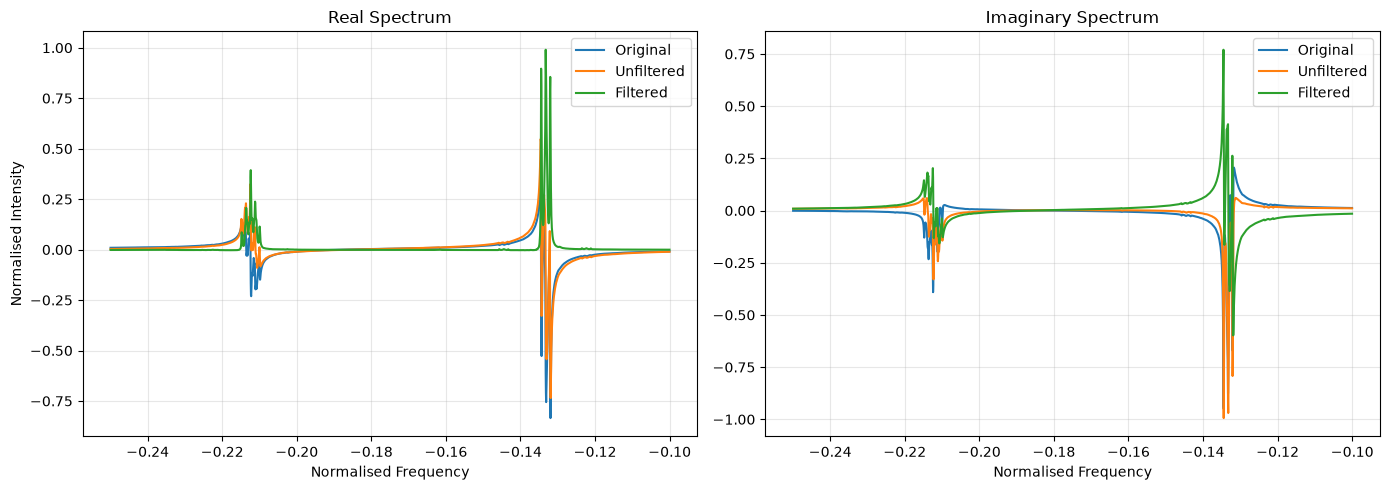

In [3]:
N_fft = 2**int(np.ceil(np.log2(len(fid))))

frequencies = np.fft.fftfreq(N_fft)
spectrum = np.fft.fft(fid, n=N_fft)

phase_estimates = {
    "Original": (0, 0),
    "Unfiltered": (p0_raw, p1_raw),
    "Filtered": (p0_filtered, p1_filtered)
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
mask = (frequencies > -0.25) & (frequencies < -0.10)

scale = np.max(np.abs(spectrum[mask]))

for label, (p0, p1) in phase_estimates.items():

    phase = p0 + p1*frequencies
    corrected = spectrum * np.exp(-1j*phase)

    axes[0].plot(frequencies[mask],corrected.real[mask] / scale,label=label)
    axes[1].plot(frequencies[mask],corrected.imag[mask] / scale,label=label)

axes[0].set_title("Real Spectrum")
axes[1].set_title("Imaginary Spectrum")

for ax in axes:
    ax.set_xlabel("Normalised Frequency")
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Normalised Intensity")

plt.tight_layout()
plt.show()

We have demonstrated this procedure works on a simple, real, spectra. Before moving on to real complex mixtures, and eventually urine/ plasma spectra, let's try a more complex molecule: Adenosine Monophosphate (AMP). This has more, and more widely spaced, resonances, with more complex coupling patterns. Let's load in this data:

In [4]:
data_path = "/home/awp509-admin/Downloads/nmrdata/bmse000005_3"

dic_amp, fid_amp = ng.bruker.read(data_path)
fid_amp = ng.bruker.remove_digital_filter(dic_amp, fid_amp)


Rank = 30
Input p1    Recovered p1    RMS Error
------------------------------------------
-180        -158.75         11.487°
-90         -78.08          6.288°
0           -0.00           0.000°
90          88.58           0.669°
180         195.66          8.375°

Rank = 40
Input p1    Recovered p1    RMS Error
------------------------------------------
-180        -198.55         11.990°
-90         -114.76         16.717°
0           0.00            0.000°
90          71.35           12.075°
180         165.77          9.100°

Rank = 50
Input p1    Recovered p1    RMS Error
------------------------------------------
-180        -178.60         0.854°
-90         -89.25          0.281°
0           0.00            0.000°
90          92.13           1.109°
180         179.54          0.324°


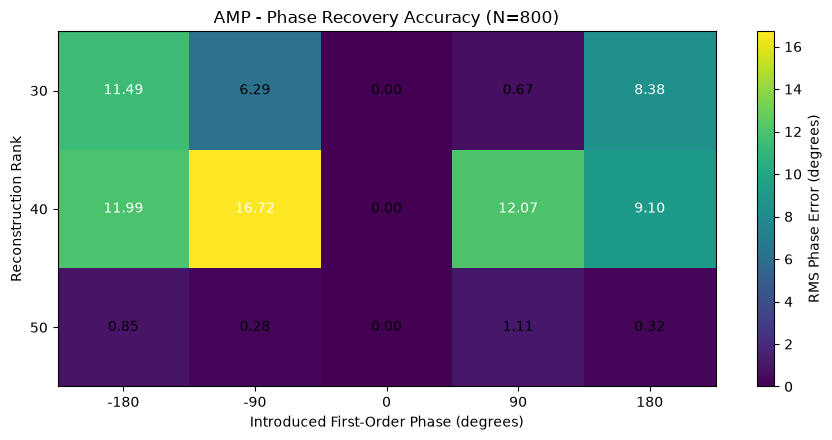

Rank 30: Median = 7.331°, Maximum = 11.487°
Rank 40: Median = 12.032°, Maximum = 16.717°
Rank 50: Median = 0.589°, Maximum = 1.109°


In [5]:
N = 800
ranks = [30, 40, 50]
p1_values = [-180, -90, 0, 90, 180]
bounds = (-4*np.pi, 4*np.pi)

f = np.linspace(-0.42, -0.10, 1000)

recovery_errors = np.full((len(ranks), len(p1_values)), np.nan)

n_fft = 2**int(np.ceil(np.log2(2*len(fid_amp))))
frequencies = np.fft.fftfreq(n_fft)
S_original = np.fft.fft(fid_amp, n=n_fft)

for i, rank in enumerate(ranks):

    p0_ref, p1_ref = pdu.retrieve_phases(fid_amp, order=rank, n_datapoints=N,method='circular', bounds=bounds, filter_decay=True)

    print(f"\nRank = {rank}")
    print(f"{'Input p1':<12}{'Recovered p1':<16}{'RMS Error'}")
    print("-" * 42)

    for j, dp1 in enumerate(p1_values):

        phase = np.deg2rad(dp1 * frequencies)

        fid_test = np.fft.ifft(S_original * np.exp(1j*phase))[:len(fid_amp)]

        p0_est, p1_est = pdu.retrieve_phases(fid_test, order=rank, n_datapoints=N,method='circular', bounds=bounds, filter_decay=True)

        delta0 = np.angle(np.exp(1j*(p0_est - p0_ref)))
        delta1 = p1_est - p1_ref

        phase_error = np.angle(np.exp(1j * (delta0 + delta1*f - np.deg2rad(dp1)*f)))

        recovery_errors[i, j] = np.degrees(np.sqrt(np.mean(phase_error**2)))

        print(
            f"{dp1:<12}"
            f"{np.degrees(delta1):<16.2f}"
            f"{recovery_errors[i,j]:.3f}°"
        )

fig, ax = plt.subplots(figsize=(9, 4.5))

im = ax.imshow(recovery_errors, aspect="auto", vmin=0)

ax.set_xticks(range(len(p1_values)))
ax.set_xticklabels(p1_values)

ax.set_yticks(range(len(ranks)))
ax.set_yticklabels(ranks)

ax.set_xlabel("Introduced First-Order Phase (degrees)")
ax.set_ylabel("Reconstruction Rank")
ax.set_title(f"AMP - Phase Recovery Accuracy (N={N})")

for i in range(len(ranks)):
    for j in range(len(p1_values)):
        ax.text(
            j, i, f"{recovery_errors[i,j]:.2f}",
            ha="center", va="center",
            color="white" if recovery_errors[i,j] > np.nanmax(recovery_errors)/2 else "black"
        )

fig.colorbar(im, ax=ax, label="RMS Phase Error (degrees)")

plt.tight_layout()
plt.show()

nonzero = np.array(p1_values) != 0

for i, rank in enumerate(ranks):

    e = recovery_errors[i, nonzero]

    print(
        f"Rank {rank}: "
        f"Median = {np.nanmedian(e):.3f}°, "
        f"Maximum = {np.nanmax(e):.3f}°"
    )

The results here are clear. Rank sensitivity is hugely improtant. We have reconstructed using only the first $800$ datapoints, and manged tor esolve the phases to within half a degree. Bruker actually gives there processing parameters with the data itself, so we can compare against a manually corrected spectra, using our rank that gave the best results ($50$).

Recovered p0: -132.90°
Recovered p1: -236.06°

Spectral RMSE: 0.003978
Correlation: 0.992098
Maximum difference: 0.160560


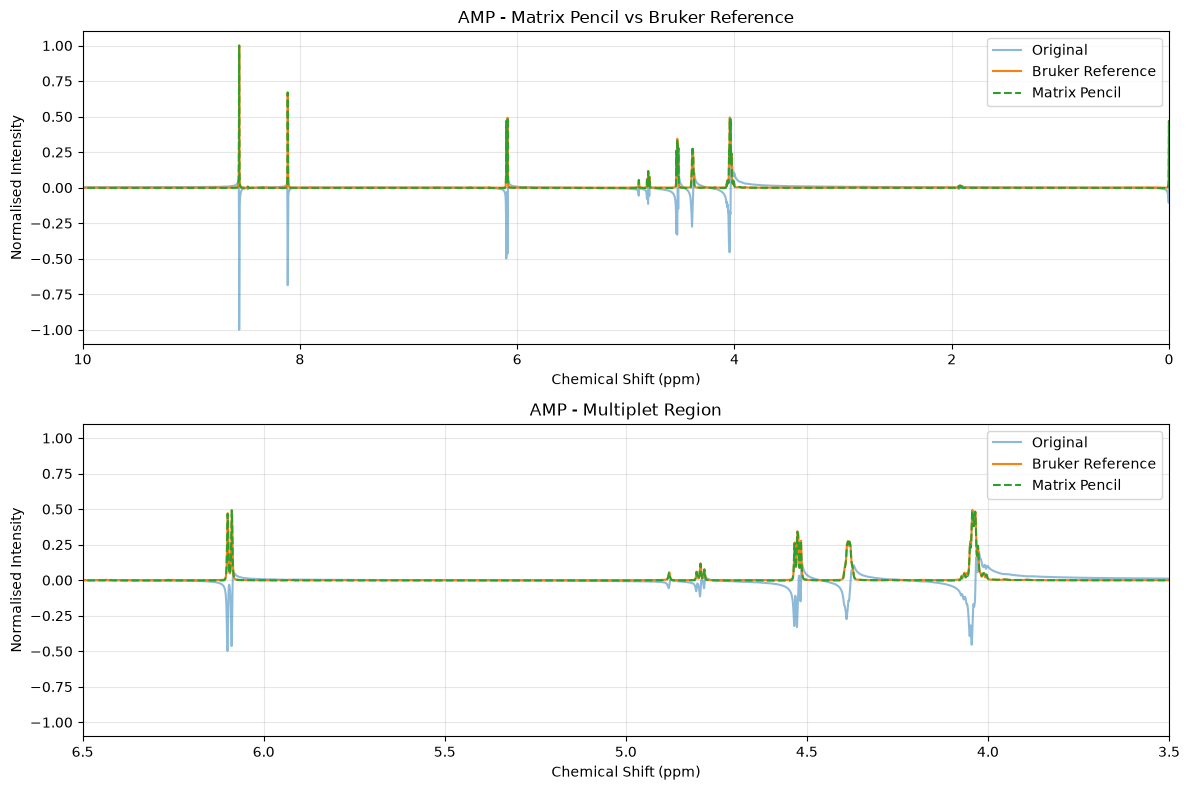

In [6]:
from pathlib import Path

N, rank = 800, 50
bounds = (-4*np.pi, 4*np.pi)

pdata_path = Path(data_path) / "pdata" / "1"
dic_ref, bruker_ref = ng.bruker.read_pdata(str(pdata_path))

udic = ng.bruker.guess_udic(dic_ref, bruker_ref)
ppm = ng.fileiobase.uc_from_udic(udic).ppm_scale()

# Additional pre-processing so we match w/ Bruker!

SI = int(dic_ref["procs"]["SI"])
LB = float(dic_ref["procs"]["LB"])
SW = float(dic_amp["acqus"]["SW_h"])

n = np.arange(len(fid_amp))
fid_windowed = fid_amp * np.exp(-np.pi * LB * n / SW)

# Back to phase correction

frequencies = np.fft.fftshift(np.fft.fftfreq(SI))
spectrum = np.fft.fftshift(np.fft.fft(fid_windowed, n=SI))

p0, p1 = pdu.retrieve_phases(fid_amp, order=rank, n_datapoints=N,method='circular', bounds=bounds, filter_decay=True)

phase = p0 + p1*frequencies
corrected = spectrum * np.exp(-1j*phase)

original = spectrum.real[::-1]
corrected = corrected.real[::-1]

original = original / np.max(np.abs(original))
corrected = corrected / np.max(np.abs(corrected))
reference = bruker_ref / np.max(np.abs(bruker_ref))

residual = corrected - reference

print(f"Recovered p0: {np.degrees(p0):.2f}°")
print(f"Recovered p1: {np.degrees(p1):.2f}°")

print(f"\nSpectral RMSE: {np.sqrt(np.mean(residual**2)):.6f}")
print(f"Correlation: {np.corrcoef(reference, corrected)[0,1]:.6f}")
print(f"Maximum difference: {np.max(np.abs(residual)):.6f}")

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

for ax in axes:

    ax.plot(ppm, original, label="Original", alpha=0.5)
    ax.plot(ppm, reference, label="Bruker Reference")
    ax.plot(ppm, corrected, "--", label="Matrix Pencil")

    ax.set_xlabel("Chemical Shift (ppm)")
    ax.set_ylabel("Normalised Intensity")
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_xlim(10, 0)
axes[0].set_title("AMP - Matrix Pencil vs Bruker Reference")

axes[1].set_xlim(6.5, 3.5)
axes[1].set_title("AMP - Multiplet Region")

plt.tight_layout()
plt.show()

This is excellent agreement! Note that we have also included the same basic pre-processing as Bruker here, but the phase correction is entirely our method, this just makes it easier to see how much they agree. I think we are ready for a harder test now. 

In [7]:
data_path = "/home/awp509-admin/Downloads/nmrdata/MTBLS12785_urine_100"

dic, fid = ng.bruker.read(data_path)
fid_urine = ng.bruker.remove_digital_filter(dic, fid)

FID datapoints: 49079
Processed Bruker reference available: True


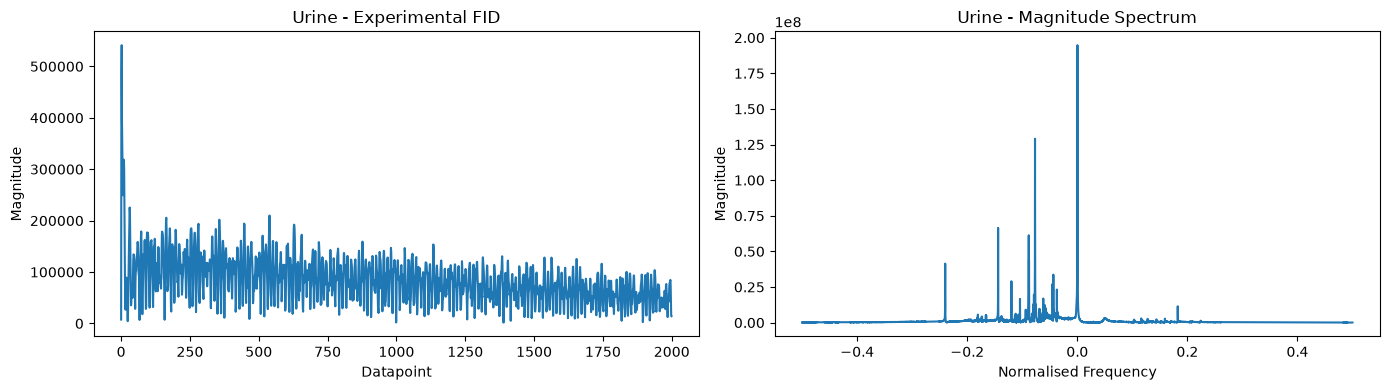

In [8]:
from pathlib import Path

# Check for processed Bruker reference
pdata_path = Path(data_path) / "pdata" / "1"
has_reference = (pdata_path / "1r").exists()

if has_reference:
    dic_ref, bruker_ref = ng.bruker.read_pdata(str(pdata_path))

    udic = ng.bruker.guess_udic(dic_ref, bruker_ref)
    ppm = ng.fileiobase.uc_from_udic(udic).ppm_scale()

print(f"FID datapoints: {len(fid_urine)}")
print(f"Processed Bruker reference available: {has_reference}")

# Fourier transform
n_fft = 2**int(np.ceil(np.log2(len(fid_urine))))
frequencies = np.fft.fftshift(np.fft.fftfreq(n_fft))
spectrum = np.fft.fftshift(np.fft.fft(fid_urine, n=n_fft))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(np.abs(fid_urine[:2000]))
axes[0].set_title("Urine - Experimental FID")
axes[0].set_xlabel("Datapoint")
axes[0].set_ylabel("Magnitude")

axes[1].plot(frequencies, np.abs(spectrum))
axes[1].set_title("Urine - Magnitude Spectrum")
axes[1].set_xlabel("Normalised Frequency")
axes[1].set_ylabel("Magnitude")

plt.tight_layout()
plt.show()

Rank    p0 (°)        p1 (°)
-----------------------------------
50      -152.50       720.00
80      161.50        720.00
120     158.98        720.00


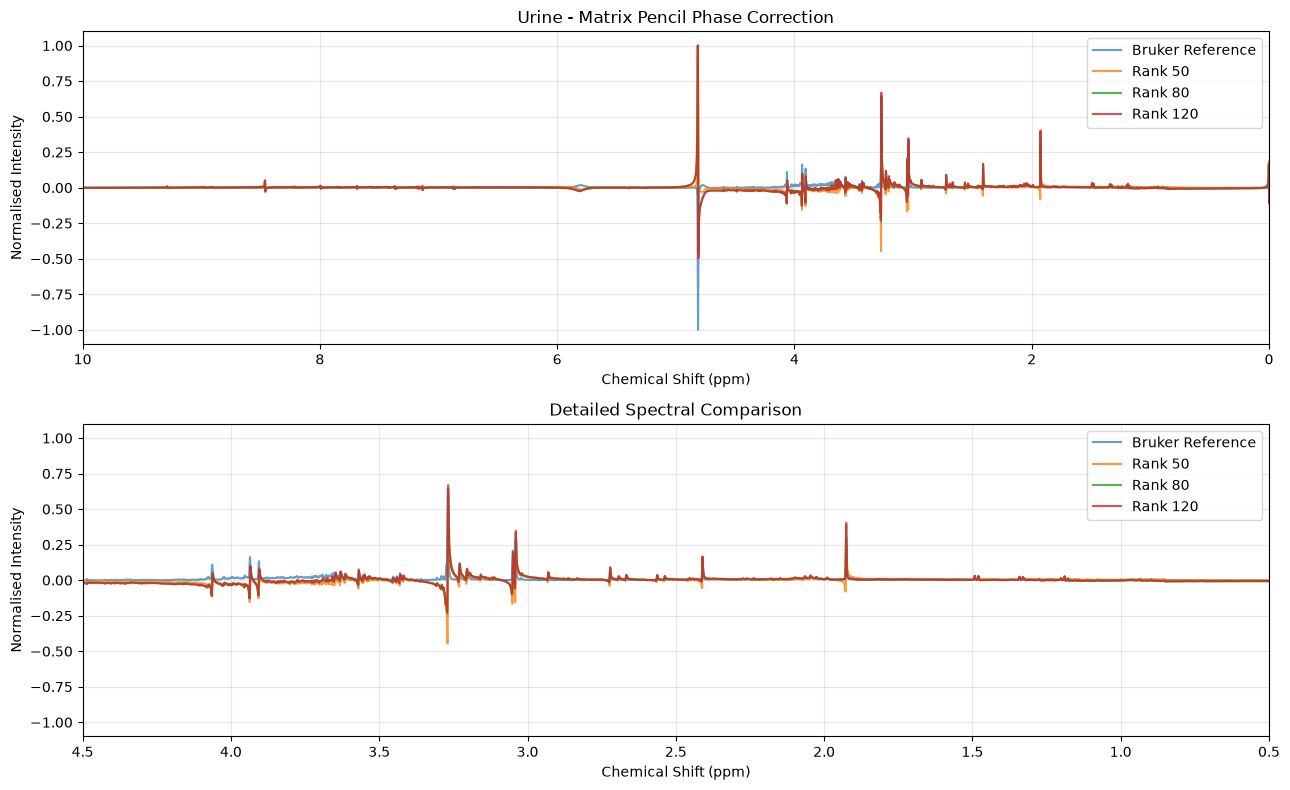

In [9]:
N = 2000
ranks = [50, 80, 120]
bounds = (-4*np.pi, 4*np.pi)

phase_estimates = {}

print(f"{'Rank':<8}{'p0 (°)':<14}{'p1 (°)'}")
print("-" * 35)

for rank in ranks:

    p0, p1 = pdu.retrieve_phases(
        fid_urine,
        order=rank,
        n_datapoints=N,
        method='circular',
        bounds=bounds,
        filter_decay=True
    )

    phase_estimates[rank] = (p0, p1)

    print(
        f"{rank:<8}"
        f"{np.degrees(p0):<14.2f}"
        f"{np.degrees(p1):.2f}"
    )


# Match Bruker processing where available
if has_reference:
    SI = int(dic_ref["procs"]["SI"])
    LB = float(dic_ref["procs"].get("LB", 0))
else:
    SI = n_fft
    LB = 0

SW = float(dic["acqus"]["SW_h"])

n = np.arange(len(fid_urine))
fid_windowed = fid_urine * np.exp(-np.pi * LB * n / SW)

frequencies = np.fft.fftshift(np.fft.fftfreq(SI))
spectrum = np.fft.fftshift(np.fft.fft(fid_windowed, n=SI))

fig, axes = plt.subplots(2, 1, figsize=(13, 8))

# Bruker reference
if has_reference and len(bruker_ref) == SI:

    reference = bruker_ref / np.max(np.abs(bruker_ref))

    for ax in axes:
        ax.plot(ppm, reference, label="Bruker Reference", alpha=0.7)


# Matrix Pencil corrections
for rank in ranks:

    p0, p1 = phase_estimates[rank]

    phase = p0 + p1*frequencies
    corrected = spectrum * np.exp(-1j*phase)

    if has_reference and len(bruker_ref) == SI:
        corrected = corrected.real[::-1]
        x = ppm
    else:
        corrected = corrected.real
        x = frequencies

    corrected = corrected / np.max(np.abs(corrected))

    for ax in axes:
        ax.plot(
            x, corrected,
            label=f"Rank {rank}",
            alpha=0.8
        )


for ax in axes:
    ax.set_ylabel("Normalised Intensity")
    ax.grid(alpha=0.3)
    ax.legend()

if has_reference and len(bruker_ref) == SI:

    axes[0].set_xlim(10, 0)
    axes[1].set_xlim(4.5, 0.5)

    for ax in axes:
        ax.set_xlabel("Chemical Shift (ppm)")

else:

    axes[0].set_xlabel("Normalised Frequency")
    axes[1].set_xlabel("Normalised Frequency")
    axes[1].set_xlim(-0.3, 0.3)

axes[0].set_title("Urine - Matrix Pencil Phase Correction")
axes[1].set_title("Detailed Spectral Comparison")

plt.tight_layout()
plt.show()

This is interesting! We can see that this isn't working, but why? This is water suppression. It has done a good job of trying to phase this spectrum as well as it can because *it doesn't know to exclude water*! It isn't some spurious resonance, it is real and decays at a sensible rate, but in the processed spectrum it gives a negative spike, which our procedure tries desparately to avoid. Let's exclude the water region from the weighting, and see if we can better reproduce the spectrum.

Water exclusion = False | p0 =  158.98° | p1 =  720.00°
Water exclusion = True  | p0 =   35.39° | p1 = -134.95°


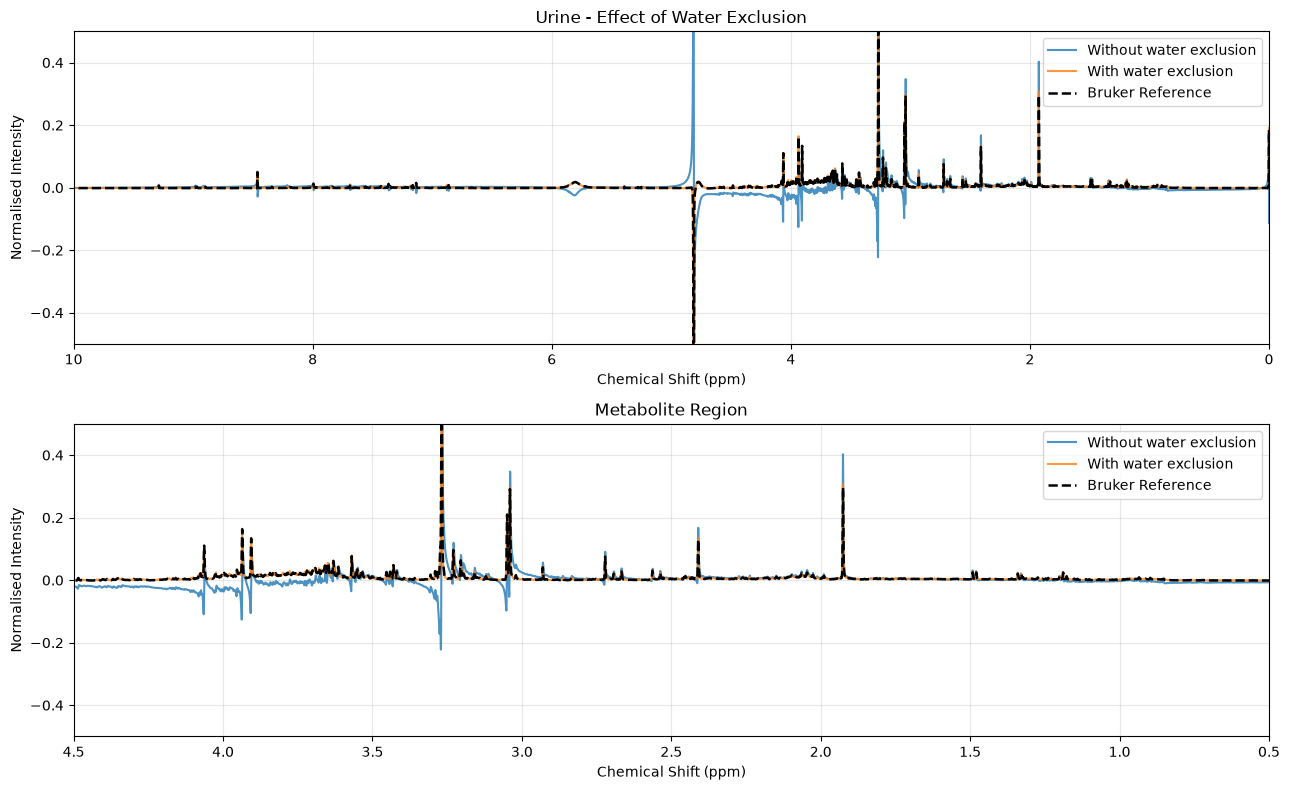

In [11]:
N, rank = 2000, 120
bounds = (-4*np.pi, 4*np.pi)

SI = int(dic_ref["procs"]["SI"])
LB = float(dic_ref["procs"]["LB"])
SF = float(dic_ref["procs"]["SF"])
SW_p = float(dic_ref["procs"]["SW_p"])
OFFSET = float(dic_ref["procs"]["OFFSET"])

SW = float(dic["acqus"]["SW_h"])
SFO1 = float(dic["acqus"]["SFO1"])

ppm_bruker = OFFSET - np.arange(SI) * SW_p / (SI * SF)

frequencies = np.fft.fftshift(np.fft.fftfreq(SI))
freq_hz = frequencies * SW

carrier_ppm = (SFO1 - SF) * 1e6 / SF
ppm_fft = carrier_ppm + freq_hz[::-1] / SF

phase_estimates = {}

for filtering in [False, True]:

    p0, p1 = pdu.retrieve_phases(fid_urine, order=rank, n_datapoints=N, method='circular', bounds=bounds, filter_decay=True, water_suppression=filtering, ppm_axis=ppm_fft)

    label = "With water exclusion" if filtering else "Without water exclusion"
    phase_estimates[label] = (p0, p1)

    print(
        f"Water exclusion = {str(filtering):<5} | "
        f"p0 = {np.degrees(p0):7.2f}° | "
        f"p1 = {np.degrees(p1):7.2f}°"
    )

n = np.arange(len(fid_urine))
fid_windowed = fid_urine * np.exp(-np.pi * LB * n / SW)
spectrum = np.fft.fftshift(np.fft.fft(fid_windowed, n=SI))

reference = bruker_ref / np.max(np.abs(bruker_ref))

fig, axes = plt.subplots(2, 1, figsize=(13, 8))


for label, (p0, p1) in phase_estimates.items():

    phase = p0 + p1 * frequencies

    corrected = spectrum * np.exp(-1j * phase)

    corrected = corrected.real[::-1]
    corrected /= np.max(np.abs(corrected))

    for ax in axes:
        ax.plot(ppm_fft, corrected, label=label, alpha=0.8)

# Plot Bruker reference LAST so it remains visible
for ax in axes:
    ax.plot(ppm_bruker, reference, label="Bruker Reference", color="black", linestyle="--", linewidth=1.8, alpha=1.0, zorder=10)

axes[0].set_xlim(10, 0)
axes[1].set_xlim(4.5, 0.5)

axes[0].set_ylim(-0.5, 0.5)
axes[1].set_ylim(-0.5, 0.5)

axes[0].set_title("Urine - Effect of Water Exclusion")
axes[1].set_title("Metabolite Region")

for ax in axes:
    ax.set_xlabel("Chemical Shift (ppm)")
    ax.set_ylabel("Normalised Intensity")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

Excellent! This was not a trivial challenge. Let's move on to a plasma spectrum- something which many modern techniques can struggle with, due it's broad resonances and peaks.

In [12]:
data_path = "/home/awp509-admin/Downloads/nmrdata/Human_Plasma_Raw_NMR_Data/CET160_BASAL/16"

dic, fid = ng.bruker.read(data_path)
fid_plasma = ng.bruker.remove_digital_filter(dic, fid)

# Load processed Bruker reference
pdata_path = Path(data_path) / "pdata" / "1"

dic_ref, bruker_ref = ng.bruker.read_pdata(str(pdata_path))

udic = ng.bruker.guess_udic(dic_ref, bruker_ref)
ppm = ng.fileiobase.uc_from_udic(udic).ppm_scale()

print(f"Pulse programme: {dic['acqus']['PULPROG']}")
print(f"FID datapoints: {len(fid_plasma)}")

for key in ["WDW", "LB", "GB", "SSB", "BC_mod", "PHC0", "PHC1"]:
    print(f"{key:<8}: {dic_ref['procs'].get(key)}")

Pulse programme: ledbpgppr2s1d
FID datapoints: 49074
WDW     : 1
LB      : 1
GB      : 0
SSB     : 0
BC_mod  : 0
PHC0    : 137.0764
PHC1    : 0


FID datapoints: 49074
Processed Bruker reference available: False


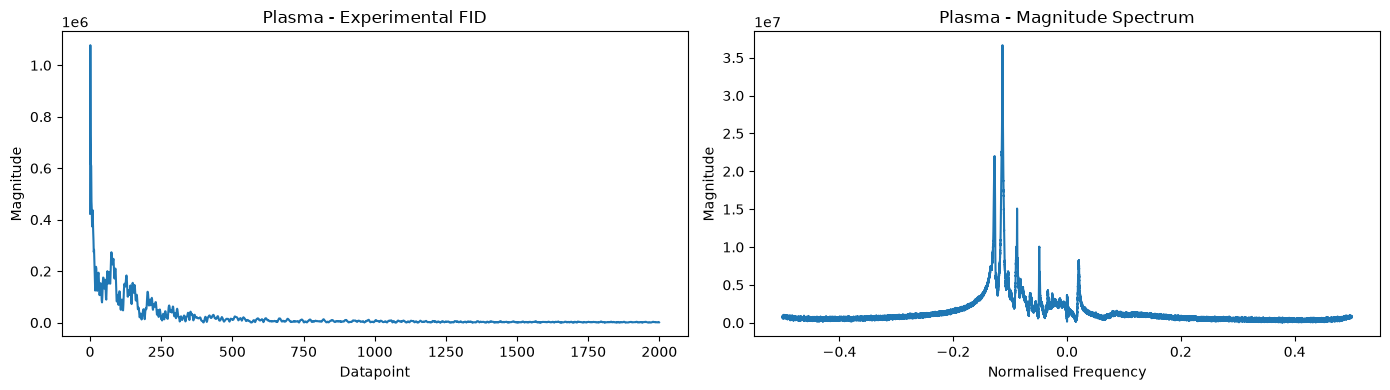

In [13]:
from pathlib import Path

# Check for processed Bruker reference
pdata_path = Path(data_path) / "pdata" / "110"
has_reference = (pdata_path / "1r").exists()

if has_reference:
    dic_ref, bruker_ref = ng.bruker.read_pdata(str(pdata_path))

    udic = ng.bruker.guess_udic(dic_ref, bruker_ref)
    ppm = ng.fileiobase.uc_from_udic(udic).ppm_scale()

print(f"FID datapoints: {len(fid_plasma)}")
print(f"Processed Bruker reference available: {has_reference}")

# Fourier transform
n_fft = 2**int(np.ceil(np.log2(len(fid_plasma))))
frequencies = np.fft.fftshift(np.fft.fftfreq(n_fft))
spectrum = np.fft.fftshift(np.fft.fft(fid_plasma, n=n_fft))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(np.abs(fid_plasma[:2000]))
axes[0].set_title("Plasma - Experimental FID")
axes[0].set_xlabel("Datapoint")
axes[0].set_ylabel("Magnitude")

axes[1].plot(frequencies, np.abs(spectrum))
axes[1].set_title("Plasma - Magnitude Spectrum")
axes[1].set_xlabel("Normalised Frequency")
axes[1].set_ylabel("Magnitude")

plt.tight_layout()
plt.show()

Pulse programme: ledbpgppr2s1d
Carrier region (ppm): 4.701678845345031

Method            p0 (°)        p1 (°)
---------------------------------------------
MAD + water       155.12        137.55
MAD only          155.22        138.46
Water only        116.79        -400.97

Method            Correlation     Normalised RMSE
-------------------------------------------------------
MAD + water       0.99826         0.010468
MAD only          0.99825         0.010519
Water only        0.89745         0.053881


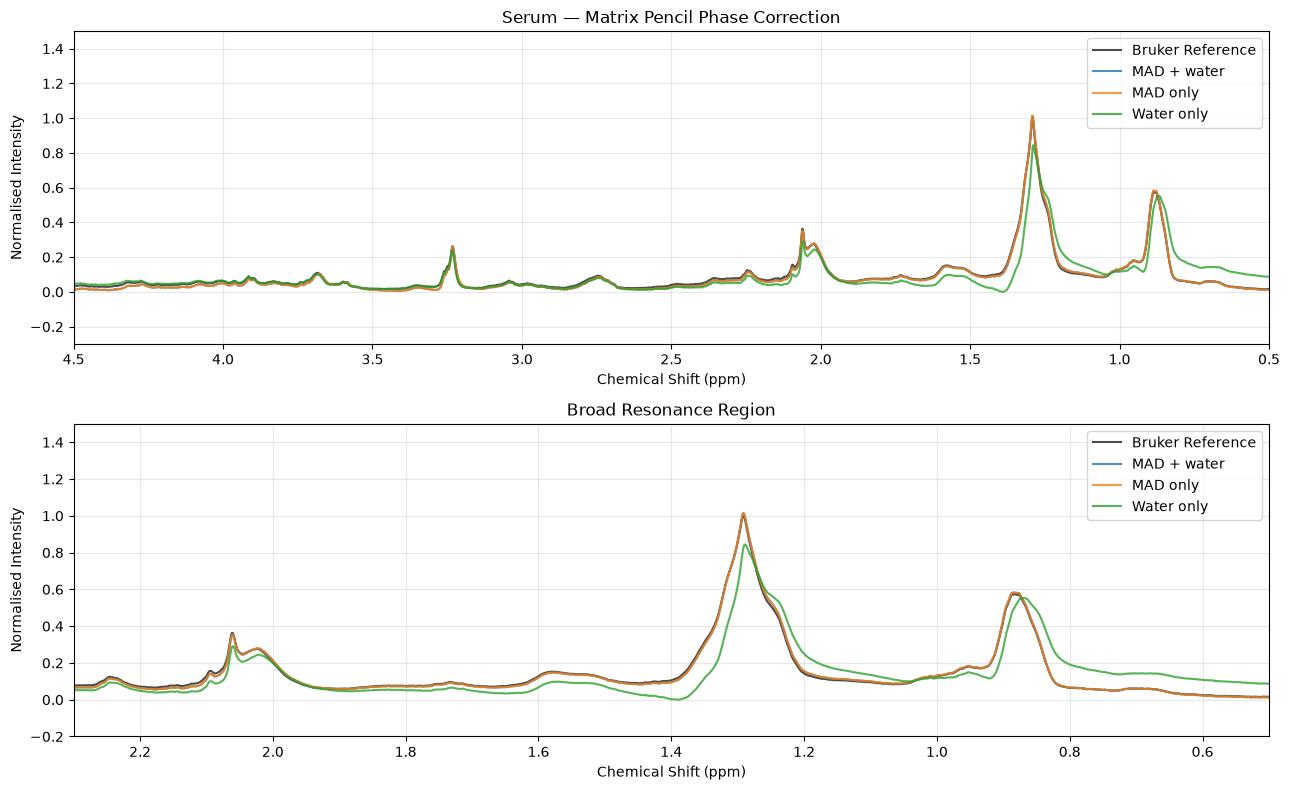

In [14]:
N, rank = 2000, 120
bounds = (-4*np.pi, 4*np.pi)

settings = [
    ("MAD + water", True, True),
    ("MAD only", True, False),
    ("Water only", False, True)
]

print("Pulse programme:", dic["acqus"].get("PULPROG"))
print("Carrier region (ppm):", ppm[len(ppm)//2])

# Estimate phases
phase_estimates = {}

print(f"\n{'Method':<18}{'p0 (°)':<14}{'p1 (°)'}")
print("-" * 45)

for label, filter_decay, water_suppression in settings:

    p0, p1 = pdu.retrieve_phases(fid_plasma, order=rank, n_datapoints=N, method='circular', bounds=bounds, filter_decay=filter_decay, water_suppression=water_suppression, ppm_axis=ppm)

    phase_estimates[label] = (p0, p1)

    print(
        f"{label:<18}"
        f"{np.degrees(p0):<14.2f}"
        f"{np.degrees(p1):.2f}"
    )


# Match Bruker processing
SI = int(dic_ref["procs"]["SI"])
LB = float(dic_ref["procs"].get("LB", 0))
SW = float(dic["acqus"]["SW_h"])

n = np.arange(len(fid_plasma))
fid_windowed = fid_plasma * np.exp(-np.pi*LB*n/SW)

frequencies = np.fft.fftshift(np.fft.fftfreq(SI))
spectrum = np.fft.fftshift(np.fft.fft(fid_windowed, n=SI))

# Use the metabolite/macromolecule region for comparison
reference = np.asarray(bruker_ref, dtype=float)
region = (ppm >= 0.5) & (ppm <= 4.5)
normalisation = np.max(np.abs(reference[region]))

fig, axes = plt.subplots(2, 1, figsize=(13, 8))

for ax in axes:
    ax.plot(ppm, reference / normalisation, label="Bruker Reference", color="black", alpha=0.7)

print(f"\n{'Method':<18}{'Correlation':<16}{'Normalised RMSE'}")
print("-" * 55)

for label, (p0, p1) in phase_estimates.items():

    phase = p0 + p1*frequencies
    corrected = spectrum * np.exp(-1j*phase)

    corrected = corrected.real[::-1]

    # Match overall amplitude using least squares
    scale = np.dot(reference[region], corrected[region]) / np.dot(corrected[region], corrected[region])

    if scale < 0:
        print(f"Warning: {label} requires a negative amplitude scale.")

    corrected = max(scale, 0) * corrected

    # Compare against Bruker
    correlation = np.corrcoef(reference[region], corrected[region])[0, 1] if scale > 0 else np.nan

    rmse = np.sqrt(np.mean((reference[region] - corrected[region])**2)) / normalisation

    print(f"{label:<18}{correlation:<16.5f}{rmse:.6f}")

    for ax in axes:
        ax.plot(ppm, corrected / normalisation, label=label, alpha=0.8)

axes[0].set_xlim(4.5, 0.5)
axes[1].set_xlim(2.3, 0.5)

axes[0].set_title("Serum - Matrix Pencil Phase Correction")
axes[1].set_title("Broad Resonance Region")

for ax in axes:
    ax.set_xlabel("Chemical Shift (ppm)")
    ax.set_ylabel("Normalised Intensity")
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylim(-0.3, 1.5)
axes[1].set_ylim(-0.2, 1.5)

plt.tight_layout()
plt.show()